In [2]:
rfm_source = pd.read_csv(
    "../data/online_retail_clean.csv",
    dtype={
        "InvoiceNo": str,
        "StockCode": str
    },
    parse_dates=["InvoiceDate"],
    low_memory=False
)

print("Rows loaded:", len(rfm_source))

rfm_source.head()

Rows loaded: 524878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
print(rfm_source["InvoiceDate"].min())
print(rfm_source["InvoiceDate"].max())

2010-12-01 08:26:00
2011-12-09 12:50:00


In [4]:
rfm_source = rfm_source[
    (rfm_source["InvoiceDate"] >= "2011-01-01") &
    (rfm_source["InvoiceDate"] < "2011-12-01")
].copy()

print("Rows in analysis period:", len(rfm_source))

Rows in analysis period: 459054


# Customer RFM Segmentation

This project uses retail transactions from January to November 2011. The analysis covers the same period as the main retail sales project.

In [5]:
print(
    "Rows with missing CustomerID:",
    rfm_source["CustomerID"].isnull().sum()
)

Rows with missing CustomerID: 109058


In [6]:
rfm_source = rfm_source.dropna(
    subset=["CustomerID"]
).copy()

rfm_source["CustomerID"] = (
    rfm_source["CustomerID"]
    .astype(int)
    .astype(str)
)

print("Rows with identified customers:", len(rfm_source))
print("Unique customers:", rfm_source["CustomerID"].nunique())

Rows with identified customers: 349996
Unique customers: 4173


## RFM Definitions

- Recency: Days since the customer's most recent purchase. Lower values indicate more recent activity.
- Frequency: Number of distinct invoices associated with the customer.
- Monetary: Total sales value associated with the customer during the analysis period.

Monetary represents sales value, not customer profitability.

In [8]:
reference_date = (
    rfm_source["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

print("Reference date:", reference_date)

Reference date: 2011-12-01 17:37:00


In [9]:
last_purchase = (
    rfm_source
    .groupby("CustomerID")["InvoiceDate"]
    .max()
)

In [10]:
frequency = (
    rfm_source
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

In [11]:
monetary = (
    rfm_source
    .groupby("CustomerID")["Revenue"]
    .sum()
)

In [12]:
rfm = pd.concat(
    [last_purchase, frequency, monetary],
    axis=1
)

rfm.columns = [
    "LastPurchase",
    "Frequency",
    "Monetary"
]

rfm = rfm.reset_index()

In [13]:
rfm["Recency"] = (
    reference_date - rfm["LastPurchase"]
).dt.days

In [14]:
rfm = rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary"
    ]
]

In [15]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,317,1,77183.60
1,12347,31,5,3373.39
2,12348,67,3,904.44
3,12349,10,1,1757.55
4,12350,302,1,334.40


In [16]:
print("RFM customer rows:", len(rfm))
print("Unique CustomerID values:", rfm["CustomerID"].nunique())

RFM customer rows: 4173
Unique CustomerID values: 4173


In [17]:
rfm[
    ["Recency", "Frequency", "Monetary"]
].describe()

,Recency,Frequency,Monetary
count,4173.000000,4173.000000,4173.000000
mean,83.555476,3.919003,1869.062000
std,88.536574,6.814460,8014.001242
min,1.000000,1.000000,2.900000
25%,16.000000,1.000000,300.040000
50%,46.000000,2.000000,643.760000
75%,129.000000,4.000000,1550.140000
max,331.000000,179.000000,259886.120000


In [18]:
rfm.to_csv(
    "../data/rfm_customers.csv",
    index=False
)

## RFM Scoring

Each metric is converted into a relative score from 1 to 4 using within-sample percentile ranks.

For Recency, lower values receive higher scores. For Frequency and Monetary, higher values receive higher scores.

In [19]:
recency_percentile = rfm["Recency"].rank(pct=True)

rfm["R_Score"] = pd.cut(
    recency_percentile,
    bins=[0, 0.25, 0.50, 0.75, 1],
    labels=[4, 3, 2, 1],
    include_lowest=True
).astype(int)

In [20]:
frequency_percentile = rfm["Frequency"].rank(pct=True)

rfm["F_Score"] = pd.cut(
    frequency_percentile,
    bins=[0, 0.25, 0.50, 0.75, 1],
    labels=[1, 2, 3, 4],
    include_lowest=True
).astype(int)

In [21]:
monetary_percentile = rfm["Monetary"].rank(pct=True)

rfm["M_Score"] = pd.cut(
    monetary_percentile,
    bins=[0, 0.25, 0.50, 0.75, 1],
    labels=[1, 2, 3, 4],
    include_lowest=True
).astype(int)

In [22]:
rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,317,1,77183.60,1,1,4
1,12347,31,5,3373.39,3,4,4
2,12348,67,3,904.44,2,3,3
3,12349,10,1,1757.55,4,1,4
4,12350,302,1,334.40,1,1,2
5,12352,28,8,2506.04,3,4,4
6,12353,195,1,89.00,1,1,1
7,12354,224,1,1079.40,1,1,3
8,12355,206,1,459.40,1,1,2
9,12356,14,3,2811.43,4,3,4


In [23]:
def classify_customer(row):

    if (
        row["R_Score"] >= 3 and
        row["F_Score"] >= 3 and
        row["M_Score"] >= 3
    ):
        return "High-value"

    elif row["R_Score"] >= 3:
        return "Recent-development"

    elif (
        row["R_Score"] <= 2 and
        row["F_Score"] >= 3 and
        row["M_Score"] >= 3
    ):
        return "At-risk valuable"

    else:
        return "Lower-priority"

In [24]:
rfm["Segment"] = rfm.apply(
    classify_customer,
    axis=1
)

In [25]:
rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "R_Score",
        "F_Score",
        "M_Score",
        "Segment"
    ]
].head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment
0,12346,317,1,77183.60,1,1,4,Lower-priority
1,12347,31,5,3373.39,3,4,4,High-value
2,12348,67,3,904.44,2,3,3,At-risk valuable
3,12349,10,1,1757.55,4,1,4,Recent-development
4,12350,302,1,334.40,1,1,2,Lower-priority
5,12352,28,8,2506.04,3,4,4,High-value
6,12353,195,1,89.00,1,1,1,Lower-priority
7,12354,224,1,1079.40,1,1,3,Lower-priority
8,12355,206,1,459.40,1,1,2,Lower-priority
9,12356,14,3,2811.43,4,3,4,High-value


## Segmentation Rules

- High-value: Relatively recent activity combined with relatively high Frequency and Monetary scores.
- Recent-development: Relatively recent activity, but not meeting all High-value conditions.
- At-risk valuable: Less recent activity combined with relatively high historical Frequency and Monetary scores.
- Lower-priority: Customers not meeting the above conditions.

These categories are analytical groupings, not proven predictions of future behaviour.

In [26]:
segment_counts = (
    rfm["Segment"]
    .value_counts()
)

segment_counts

Lower-priority        1678
High-value            1201
Recent-development     879
At-risk valuable       415
Name: Segment, dtype: int64

In [27]:
segment_customer_share = (
    segment_counts / len(rfm) * 100
).round(2)

segment_customer_share

Lower-priority        40.21
High-value            28.78
Recent-development    21.06
At-risk valuable       9.94
Name: Segment, dtype: float64

In [28]:
segment_count = (
    rfm.groupby("Segment")["CustomerID"]
    .count()
)

segment_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
)

segment_avg_recency = (
    rfm.groupby("Segment")["Recency"]
    .mean()
)

segment_avg_frequency = (
    rfm.groupby("Segment")["Frequency"]
    .mean()
)

segment_avg_monetary = (
    rfm.groupby("Segment")["Monetary"]
    .mean()
)

In [29]:
segment_summary = pd.concat(
    [
        segment_count,
        segment_revenue,
        segment_avg_recency,
        segment_avg_frequency,
        segment_avg_monetary
    ],
    axis=1
)

segment_summary.columns = [
    "CustomerCount",
    "TotalRevenue",
    "AvgRecency",
    "AvgFrequency",
    "AvgMonetary"
]

segment_summary = segment_summary.reset_index()

In [30]:
segment_summary["RevenueSharePct"] = (
    segment_summary["TotalRevenue"] /
    segment_summary["TotalRevenue"].sum()
    * 100
)

In [31]:
segment_summary[
    ["TotalRevenue", "AvgRecency", "AvgFrequency", "AvgMonetary"]
] = segment_summary[
    ["TotalRevenue", "AvgRecency", "AvgFrequency", "AvgMonetary"]
].round(2)

segment_summary["RevenueSharePct"] = (
    segment_summary["RevenueSharePct"].round(2)
)

segment_summary = segment_summary.sort_values(
    "TotalRevenue",
    ascending=False
)

segment_summary

,Segment,CustomerCount,TotalRevenue,AvgRecency,AvgFrequency,AvgMonetary,RevenueSharePct
1,High-value,1201,5653999.59,16.02,8.79,4707.74,72.49
0,At-risk valuable,415,866768.26,93.59,4.58,2088.60,11.11
2,Lower-priority,1678,849804.73,162.03,1.44,506.44,10.90
3,Recent-development,879,429023.14,21.29,1.70,488.08,5.50


In [32]:
segment_summary.to_csv(
    "../data/segment_summary.csv",
    index=False
)

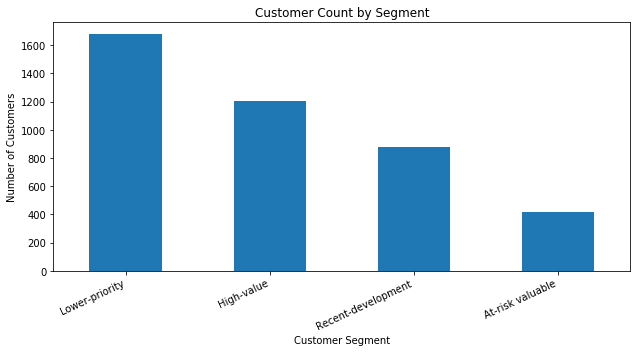

In [33]:
segment_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Count by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    "../charts/customer_count_by_segment.png",
    dpi=150
)

plt.show()

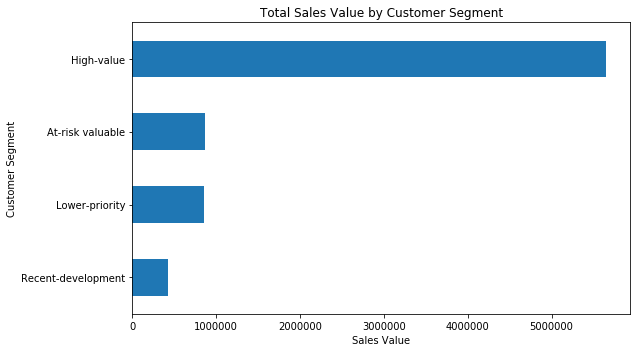

In [34]:
segment_revenue.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Total Sales Value by Customer Segment")
plt.xlabel("Sales Value")
plt.ylabel("Customer Segment")
plt.tight_layout()

plt.savefig(
    "../charts/segment_sales_value.png",
    dpi=150
)

plt.show()

In [35]:
identified_customers = rfm["CustomerID"].nunique()

largest_segment = segment_counts.idxmax()

highest_sales_segment = segment_revenue.idxmax()

print("Identified customers:", identified_customers)
print("Largest segment by customer count:", largest_segment)
print("Highest-sales-value segment:", highest_sales_segment)

Identified customers: 4173
Largest segment by customer count: Lower-priority
Highest-sales-value segment: High-value


## Potential Marketing Actions

- High-value: Consider loyalty benefits, priority service and early access to selected products.
- Recent-development: Consider relevant product recommendations and initiatives that encourage repeat purchases.
- At-risk valuable: Consider targeted reactivation and further investigation of changes in purchasing behaviour.
- Lower-priority: Consider lower-cost automated communication rather than high-cost personalised campaigns.

These are potential actions. Their effectiveness would require further testing and additional business data.